# Etapa 3 — Modelagem

Entrada: `../data/processed/dataset.csv`, da Etapa 2.
Saída: um classificador treinado, avaliado e interpretado, e um ranking dos
melhores horários da janela.

Um detalhe que define esta etapa: **não existe label pronta.** O site
classifica as condições para pesca, não para surf — e pesca gosta de mar
calmo, quase o oposto. Definir o que é uma condição boa para surfar é a
primeira tarefa aqui, e é uma decisão sua.

In [17]:
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DIR_PROC = Path("..") / "data" / "processed"


## 1. Carregar o dataset processado

Confira que veio o que você espera: número de linhas, tipos, nulos. Se a
Etapa 2 mudou, isso aparece aqui.

In [3]:
caminho_dataset = DIR_PROC / "dataset.csv"
df = pd.read_csv(caminho_dataset)
print(f"Número de linhas e colunas: {df.shape}")
display(df.info())
display(df.head())

Número de linhas e colunas: (168, 13)
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   datetime        168 non-null    str    
 1   altura_m        168 non-null    float64
 2   direcao_onda    168 non-null    str    
 3   hora_dia        168 non-null    int64  
 4   velocidade_kmh  168 non-null    float64
 5   direcao_vento   168 non-null    str    
 6   altura_mare_m   168 non-null    float64
 7   variacao_mare   167 non-null    float64
 8   mare_subindo    168 non-null    str    
 9   hora            168 non-null    int64  
 10  dia_semana      168 non-null    str    
 11  data            168 non-null    str    
 12  mes             168 non-null    int64  
dtypes: float64(4), int64(3), str(6)
memory usage: 17.2 KB


None

,datetime,altura_m,direcao_onda,hora_dia,velocidade_kmh,direcao_vento,altura_mare_m,variacao_mare,mare_subindo,hora,dia_semana,data,mes
0,2026-10-09 00:00:00,1.0,ESE,0,23.0,SE,1.500538,NaN,estável ou indeterminada,0,Sexta-feira,2026-10-09,10
1,2026-10-09 01:00:00,1.0,ESE,1,22.0,SE,1.855376,0.354839,subindo,1,Sexta-feira,2026-10-09,10
2,2026-10-09 02:00:00,1.0,ESE,2,23.0,SE,2.210215,0.354839,subindo,2,Sexta-feira,2026-10-09,10
3,2026-10-09 03:00:00,1.0,ESE,3,24.0,SE,2.434946,0.224731,subindo,3,Sexta-feira,2026-10-09,10
4,2026-10-09 04:00:00,1.0,ESE,4,24.0,ESE,2.080108,-0.354839,descendo,4,Sexta-feira,2026-10-09,10


## 2. Definir a label

Escreva, em código, a regra que separa condições ruins, boas e ótimas (ou
outro conjunto de classes, se preferir).

- Quais variáveis entram na regra: altura da onda, vento, maré, direção?
- Quais limiares? De onde vem o número — leitura, conversa com surfista,
  distribuição dos próprios dados? Registre a origem, mesmo que seja um chute
  informado.
- Como as classes ficaram distribuídas? Se 95% das horas caírem numa classe,
  a métrica do modelo vai mentir para você.

Documente a regra em markdown antes de seguir. Tudo depois disso depende dela.

Regras:

Com base na análise realizada na fase 2 e por questões intuitivas, levam-se em consideração fatores como altura e vento para supor-se as melhores condições. Assim, novamente com auxílio de ferramentas de IA, separei o cenário em três partes principais:
    - Cenário ótimo (2): altura maior ou igual a 1.2 m e vento menor ou igual a 20 km/h;
    - Cenário bom (1): altura maior ou igual a 1 m e vento menor ou igual a 24 km/h;
    - Cenário ruim (0): caso os outros requisitos não sejam cumpridos.

Quanto à distribuição das classes, tem-se: 
    - (1)    60.119048;
    - (0)    22.023810;
    - (2)    17.857143.


In [5]:
def classifica_surf(row):
    altura = row['altura_m']
    vento = row['velocidade_kmh']
    if altura >= 1.2 and vento <= 20:
        return 2  
    elif altura >= 1.0 and vento <= 24:
        return 1  
    else:
        return 0  

df['surf_target'] = df.apply(classifica_surf, axis=1)

In [6]:
print("Distribuição das classes criadas:")
print(df['surf_target'].value_counts(normalize=True) * 100)

Distribuição das classes criadas:
surf_target
1    60.119048
0    22.023810
2    17.857143
Name: proportion, dtype: float64


## 3. Features e alvo

Separe `X` e `y`.

- Quais colunas entram como feature? Cuidado: usar diretamente as variáveis da
  sua regra faz o modelo apenas redescobrir o `if` que você escreveu. Isso é
  esperado aqui — mas você precisa saber que é isso que está acontecendo.
- Direção do vento e da onda são texto. Como transformar em número sem inventar
  uma ordem que não existe?

In [7]:
y = df['surf_target'].values
features_numericas = ['altura_m', 'velocidade_kmh', 'altura_mare_m', 'hora']
df_features = pd.get_dummies(df[['altura_m', 'velocidade_kmh', 'altura_mare_m', 'hora', 'direcao_onda', 'direcao_vento']], drop_first=True)
X = df_features.values

In [8]:
print(f"Formato de X (features): {X.shape}")
print(f"Formato de y (alvo): {y.shape}")
print(f"Colunas utilizadas como features: {list(df_features.columns)}")

Formato de X (features): (168, 7)
Formato de y (alvo): (168,)
Colunas utilizadas como features: ['altura_m', 'velocidade_kmh', 'altura_mare_m', 'hora', 'direcao_onda_ESE', 'direcao_vento_ESE', 'direcao_vento_SE']


## 4. Treino e teste

Divida os dados. Vale estratificar pelas classes? A ordem temporal importa —
sortear linhas de um mesmo dia entre treino e teste vaza informação?

In [10]:
split_index = int(len(X) * 0.8)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

In [11]:
print(f"Tamanho do conjunto de treino (X_train): {X_train.shape[0]} linhas")
print(f"Tamanho do conjunto de teste (X_test): {X_test.shape[0]} linhas")
print(f"Distribuição das classes no treino: {np.unique(y_train, return_counts=True)}")
print(f"Distribuição das classes no teste: {np.unique(y_test, return_counts=True)}")

Tamanho do conjunto de treino (X_train): 134 linhas
Tamanho do conjunto de teste (X_test): 34 linhas
Distribuição das classes no treino: (array([0, 1, 2]), array([36, 81, 17]))
Distribuição das classes no teste: (array([0, 1, 2]), array([ 1, 20, 13]))


## 5. Treinar

Treine pelo menos dois modelos de famílias diferentes (por exemplo uma árvore
e um modelo baseado em distância) para ter com o que comparar.

In [13]:
# modelo 1 - arvore

modelo_arvore = DecisionTreeClassifier(random_state=42, max_depth=4)
modelo_arvore.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [14]:
# modelo 2 - baseado em distancia

modelo_logistico = LogisticRegression(max_iter=1000, random_state=42)
modelo_logistico.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

## 6. Avaliar

- Acurácia é suficiente aqui, com as classes desbalanceadas como estão?
- Olhe a matriz de confusão: que erro o modelo comete?
- Um único split é confiável com poucas linhas, ou vale validação cruzada?

In [15]:
y_pred_arvore = modelo_arvore.predict(X_test)
y_pred_logistico = modelo_logistico.predict(X_test)
acc_arvore = accuracy_score(y_test, y_pred_arvore)
acc_logistico = accuracy_score(y_test, y_pred_logistico)

In [16]:
print(f"Acurácia modelo 1: {acc_arvore * 100:.2f}%")
print(f"Acurácia modelo 2: {acc_logistico * 100:.2f}%")

print("\nRelatório de Classificação (Árvore de Decisão):")
print(classification_report(y_test, y_pred_arvore, zero_division=0))

Acurácia da Árvore de Decisão: 100.00%
Acurácia da Regressão Logística: 100.00%

Relatório de Classificação (Árvore de Decisão):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00        20
           2       1.00      1.00      1.00        13

    accuracy                           1.00        34
   macro avg       1.00      1.00      1.00        34
weighted avg       1.00      1.00      1.00        34



## 7. Interpretar

Um modelo que acerta e você não sabe por quê não serve para responder nada.

- Plote a árvore. Os cortes que ela encontrou parecem com os seus limiares?
- Quais features o modelo considera mais importantes? Bate com sua intuição?
- Se a acurácia veio altíssima, explique o motivo — não celebre.

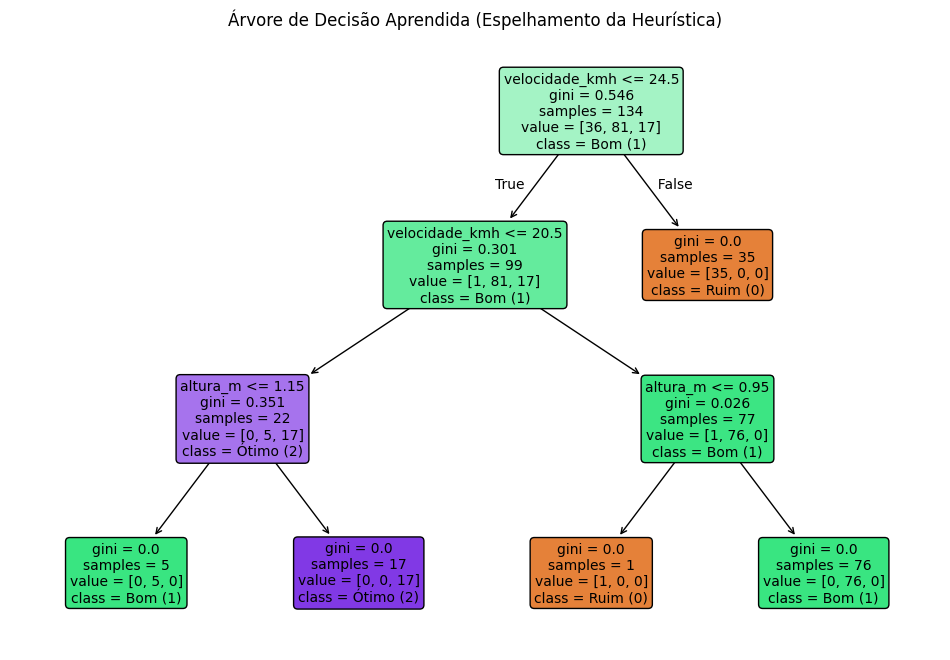

In [18]:
plt.figure(figsize=(12, 8))
plot_tree(
    modelo_arvore, 
    feature_names=list(df_features.columns), 
    class_names=['Ruim (0)', 'Bom (1)', 'Ótimo (2)'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão Aprendida (Espelhamento da Heurística)")
plt.show()

## 8. Responder a pergunta

Aplique o modelo na janela inteira e produza a resposta para Felipe e Nicholas:

- Quais os melhores dias da janela de previsão?
- Em média, qual o melhor horário do dia?
- Em que grau essa resposta é uma previsão do mar, e em que grau é apenas a
  sua regra reescrita?

In [19]:
df['surf_predito'] = modelo_arvore.predict(X)
mapeamento_classes = {0: 'Ruim', 1: 'Bom', 2: 'Ótimo'}
df['condicao_surf'] = df['surf_predito'].map(mapeamento_classes)

In [20]:
print("--- RESUMO DAS CONDIÇÕES NA JANELA ---")
print(df['condicao_surf'].value_counts())

melhores_momentos = df[df['surf_predito'] == 2][['datetime', 'altura_m', 'velocidade_kmh', 'direcao_onda', 'direcao_vento']]

print("\n--- MELHORES HORÁRIOS PARA SURFAR (ÓTIMO) ---")
display(melhores_momentos.head(10))

--- RESUMO DAS CONDIÇÕES NA JANELA ---
condicao_surf
Bom      101
Ruim      37
Ótimo     30
Name: count, dtype: int64

--- MELHORES HORÁRIOS PARA SURFAR (ÓTIMO) ---


,datetime,altura_m,velocidade_kmh,direcao_onda,direcao_vento
75,2026-10-12 03:00:00,1.2,20.0,E,ESE
88,2026-10-12 16:00:00,1.2,20.0,E,ESE
89,2026-10-12 17:00:00,1.2,20.0,E,ESE
90,2026-10-12 18:00:00,1.2,20.0,E,ESE
109,2026-10-13 13:00:00,1.3,18.0,E,ESE
110,2026-10-13 14:00:00,1.3,17.0,E,ESE
111,2026-10-13 15:00:00,1.3,17.0,E,SE
112,2026-10-13 16:00:00,1.2,19.0,E,SE
120,2026-10-14 00:00:00,1.3,19.0,E,ESE
121,2026-10-14 01:00:00,1.3,17.0,E,ESE


## 9. Conclusão e limites

Em texto:

1. A recomendação, em uma frase.
2. O teto deste modelo: ele reproduz a sua heurística, então é tão bom quanto
   ela. O que faria dela uma regra melhor?
3. O que a janela de ~7 dias e o volume de linhas impedem de afirmar.
4. Como você responderia "qual a melhor época do ano para surfar em João
   Pessoa" — que dado faltaria, e como coletá-lo.